In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("retail_store_sales_cleaned.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (10531, 11)
Missing values: 0


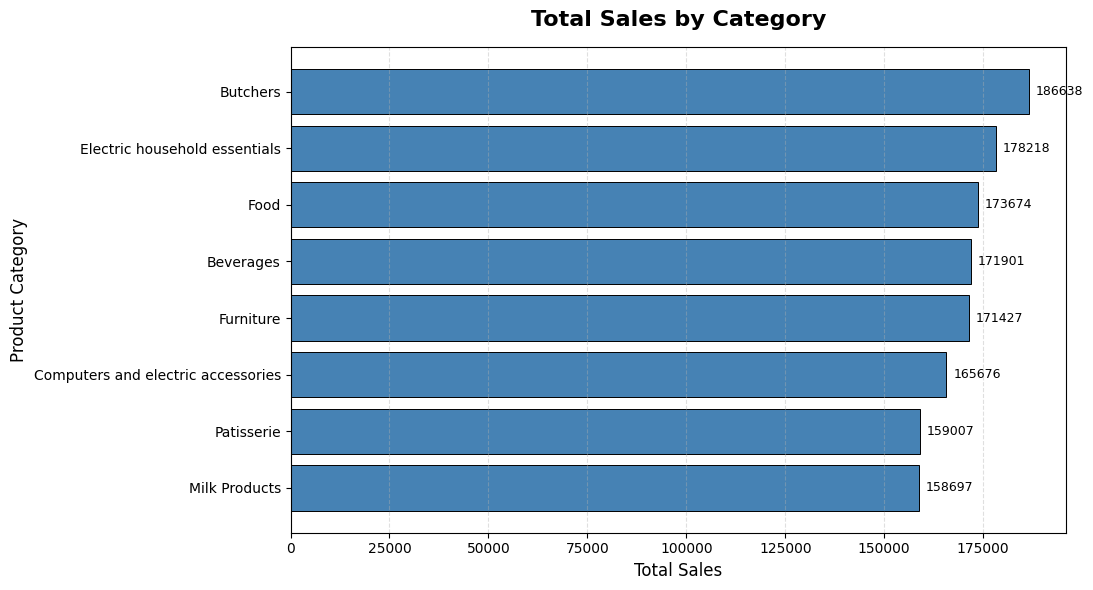

In [2]:
category_sales = (
    df.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    category_sales.index,
    category_sales.values,
    color="steelblue",
    edgecolor="black",
    linewidth=0.7
)

plt.title("Total Sales by Category", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Total Sales", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.bar_label(bars, fmt="%.0f", padding=5, fontsize=9)

plt.tight_layout()
plt.show()

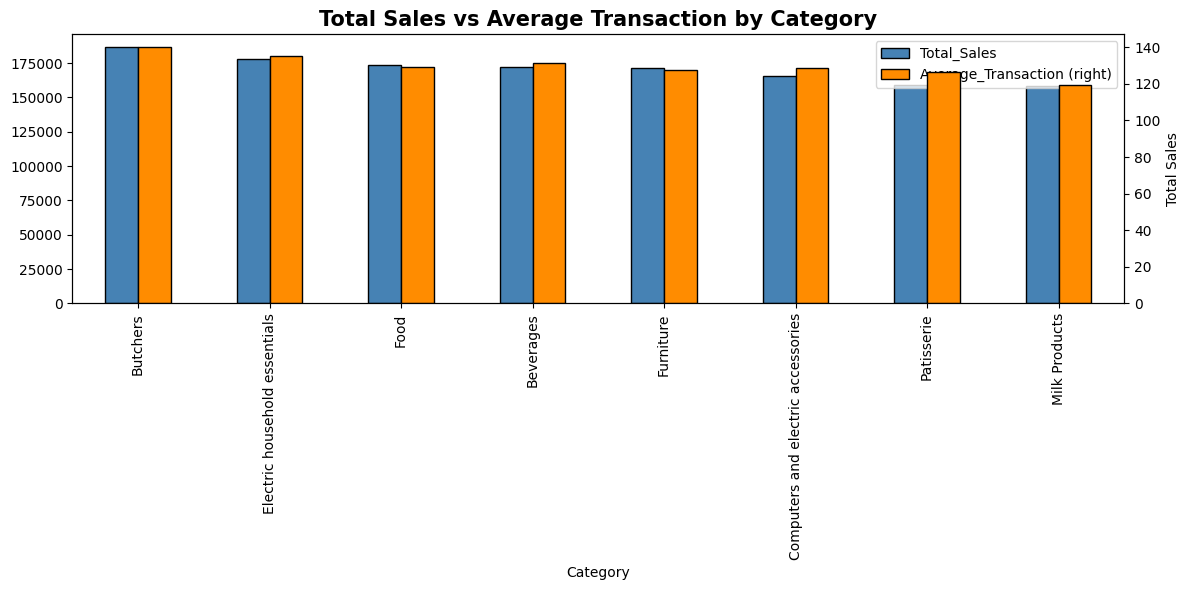

In [3]:
category_metrics = df.groupby("Category")["Total Spent"].agg(
    Total_Sales="sum",
    Average_Transaction="mean"
).sort_values("Total_Sales", ascending=False)

category_metrics.plot(
    kind="bar",
    figsize=(12, 6),
    secondary_y="Average_Transaction",
    color=["steelblue", "darkorange"],
    edgecolor="black"
)

plt.title("Total Sales vs Average Transaction by Category",
          fontsize=15, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

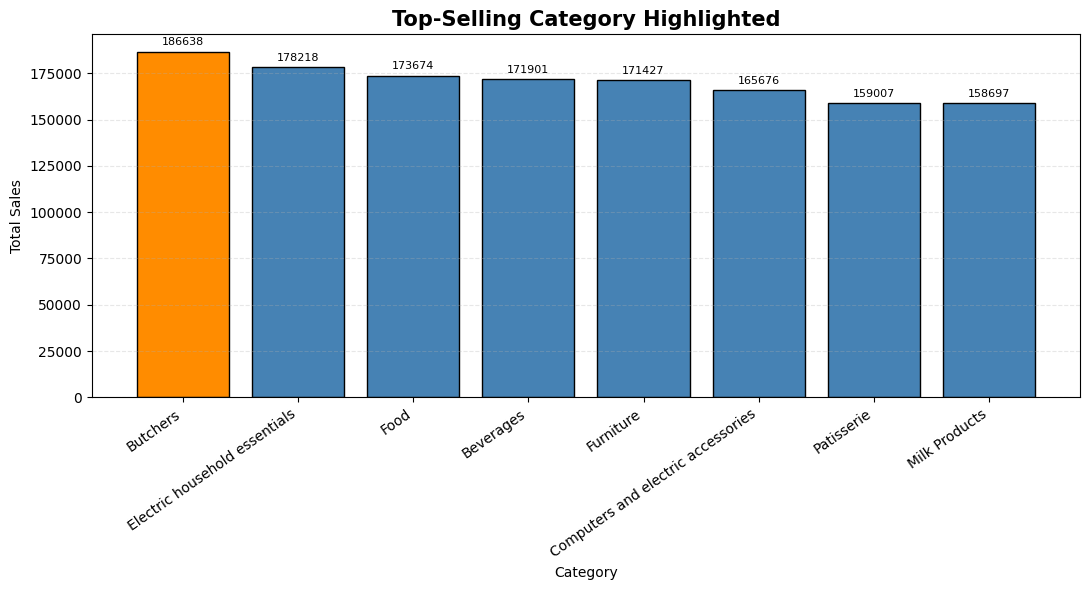

In [4]:
category_sales = (
    df.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

colors = [
    "darkorange" if category == category_sales.index[0] else "steelblue"
    for category in category_sales.index
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=colors,
    edgecolor="black"
)

plt.title("Top-Selling Category Highlighted",
          fontsize=15, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=35, ha="right")
plt.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

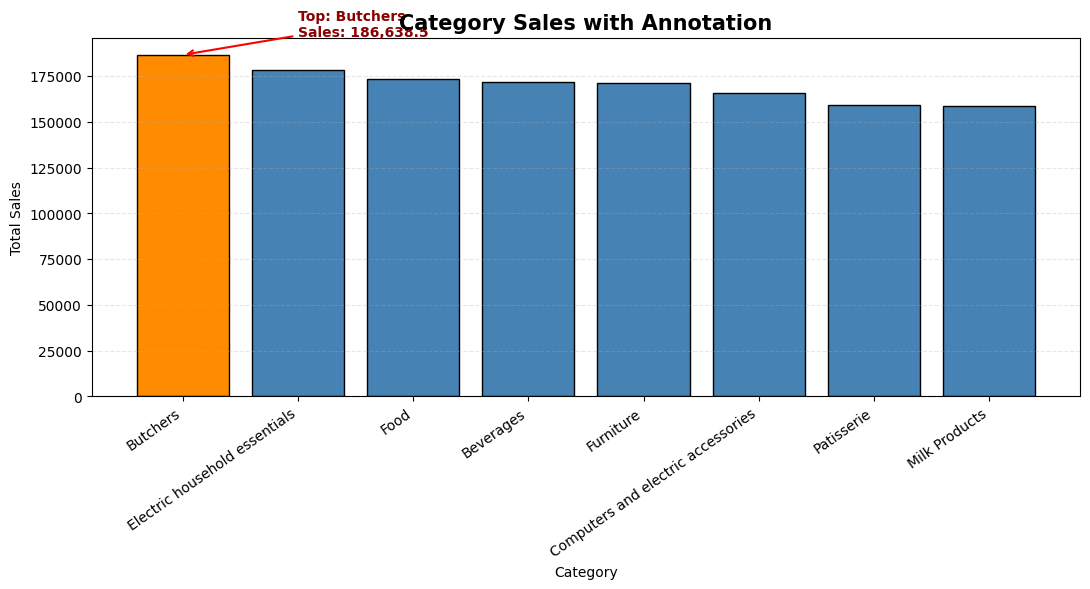

In [5]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=colors,
    edgecolor="black"
)

top_category = category_sales.index[0]
top_sales = category_sales.iloc[0]
top_position = 0

plt.annotate(
    f"Top: {top_category}\nSales: {top_sales:,.1f}",
    xy=(top_position, top_sales),
    xytext=(top_position + 1, top_sales + 10000),
    arrowprops=dict(arrowstyle="->", color="red", linewidth=1.5),
    fontsize=10,
    color="darkred",
    fontweight="bold"
)

plt.title("Category Sales with Annotation", fontsize=15, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

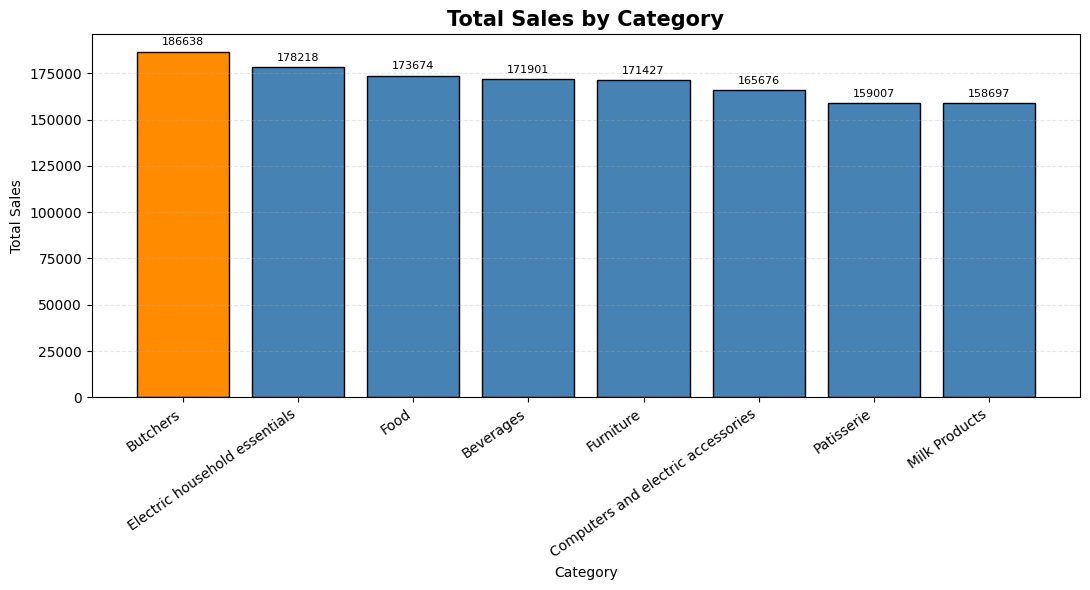

Chart saved successfully!


In [6]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=colors,
    edgecolor="black"
)

plt.title("Total Sales by Category", fontsize=15, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=35, ha="right")
plt.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig("day47_category_sales.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")

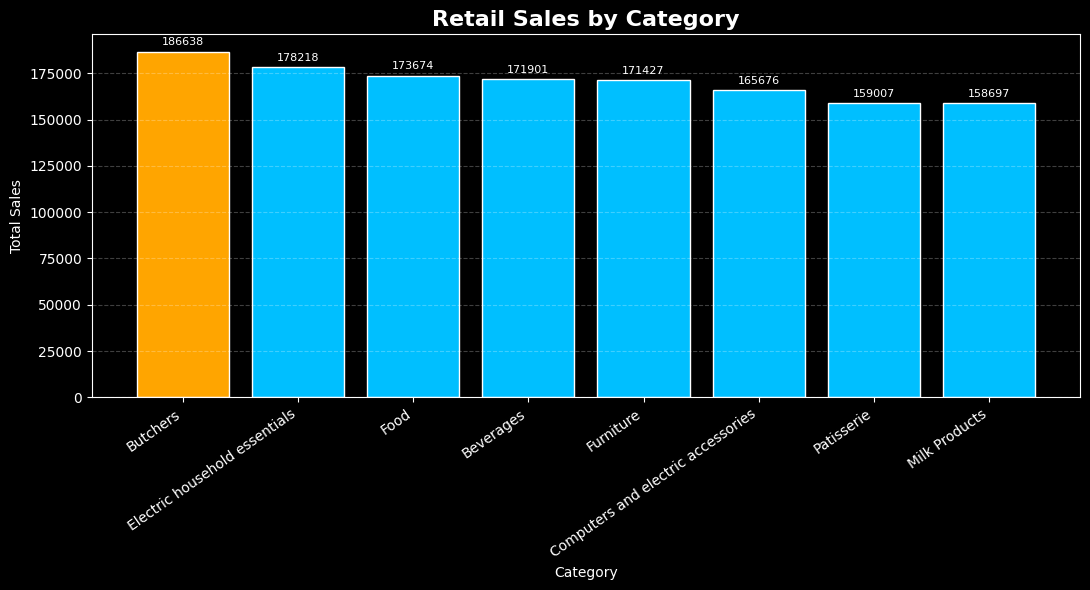

In [7]:
plt.style.use("dark_background")

plt.figure(figsize=(11, 6))

bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=["orange" if i == 0 else "deepskyblue"
           for i in range(len(category_sales))],
    edgecolor="white"
)

plt.title("Retail Sales by Category", fontsize=16, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=35, ha="right")
plt.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
plt.grid(axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()

plt.style.use("default")